In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/diabetes.csv')

# Display first 5 rows
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [2]:
# Number of rows and columns
print(df.shape)

# Column names
print(df.columns)

# Dataset information
df.info()

(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [4]:
print(df['Outcome'].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


In [5]:
print(df['Outcome'].value_counts(normalize=True) * 100)

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


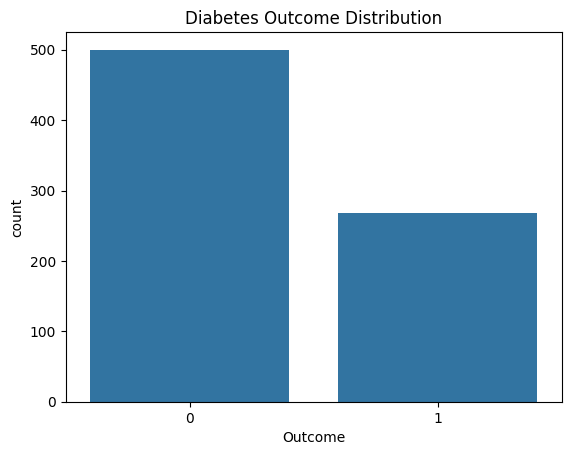

In [6]:
sns.countplot(x='Outcome', data=df)
plt.title('Diabetes Outcome Distribution')
plt.show()

In [7]:
# Calculate correlation
correlation = df.corr()

# Display correlation with Outcome
print(correlation['Outcome'].sort_values(ascending=False))

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


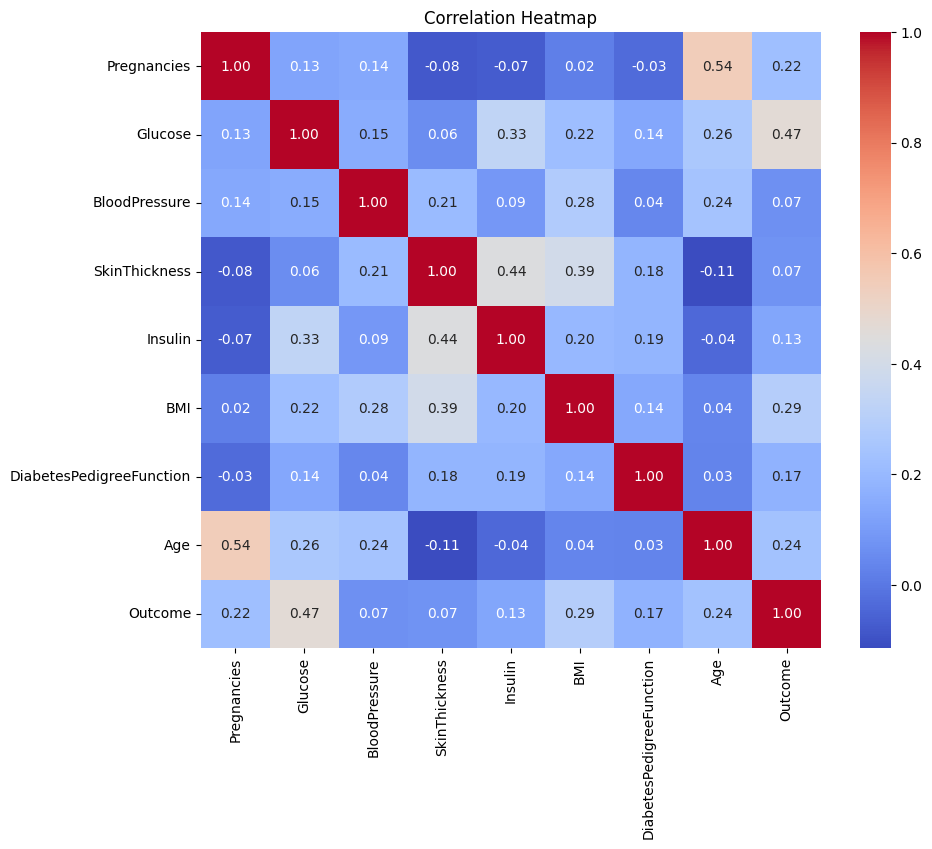

In [8]:
plt.figure(figsize=(10, 8))

sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [9]:
print(correlation['Outcome'].sort_values())

BloodPressure               0.065068
SkinThickness               0.074752
Insulin                     0.130548
DiabetesPedigreeFunction    0.173844
Pregnancies                 0.221898
Age                         0.238356
BMI                         0.292695
Glucose                     0.466581
Outcome                     1.000000
Name: Outcome, dtype: float64


In [10]:
# Check zero values in selected columns

columns = ['Glucose', 'BloodPressure',
           'SkinThickness', 'Insulin', 'BMI']

for col in columns:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [11]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [12]:
# Replace invalid zeros with NaN

columns = ['Glucose', 'BloodPressure',
           'SkinThickness', 'Insulin', 'BMI']

df[columns] = df[columns].replace(0, np.nan)

# Check missing values
print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [13]:
# Separate input features and target

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [15]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


In [16]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(imputer.fit_transform(X_train),columns=X_train.columns,index=X_train.index)

X_test = pd.DataFrame(imputer.transform(X_test),columns=X_test.columns,index=X_test.index)

In [17]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
print("Original training data:")
print(X_train.head())

print("\nScaled training data:")
print(X_train_scaled[:5])

Original training data:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
353          1.0     90.0           62.0           12.0     43.0  27.2   
711          5.0    126.0           78.0           27.0     22.0  29.6   
373          2.0    105.0           58.0           40.0     94.0  34.9   
46           1.0    146.0           56.0           29.0    125.0  29.7   
682          0.0     95.0           64.0           39.0    105.0  44.6   

     DiabetesPedigreeFunction   Age  
353                     0.580  24.0  
711                     0.439  40.0  
373                     0.225  25.0  
46                      0.564  29.0  
682                     0.366  22.0  

Scaled training data:
[[-0.85135507 -1.05642747 -0.82674004 -1.91818693 -1.20336073 -0.76969431
   0.31079384 -0.79216928]
 [ 0.35657564  0.14439907  0.47777235 -0.22987447 -1.47019479 -0.41771394
  -0.11643851  0.56103382]
 [-0.5493724  -0.55608308 -1.15286813  1.23332967 -0.55533518  0.35957603
  -0

In [20]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', random_state=42)

In [21]:
y_pred = model.predict(X_test_scaled)
print(y_pred)

[1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0
 0 1 1 0 0 0 0 0 1 0 0 1 0 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 1 0 1 0 0 0 1 0 0 0 0 1 1 0 0 1 1 0 0 1 1 1 1 1 0 0 0 0 0 1 0 1 0 1 1 1
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 1 1
 1 0 0 0 1 0]


In [22]:
comparison = pd.DataFrame({'Actual': y_test.values,'Predicted': y_pred})
print(comparison.head(10))

   Actual  Predicted
0       0          1
1       0          0
2       0          0
3       1          0
4       0          0
5       0          0
6       1          1
7       1          1
8       0          0
9       0          1


In [23]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[75 25]
 [16 38]]


In [24]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7337662337662337
Precision: 0.6031746031746031
Recall: 0.7037037037037037
F1 Score: 0.6495726495726496


In [25]:
from sklearn.metrics import roc_auc_score, roc_curve

# Get the probability of class 1
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC-AUC
auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.8125925925925926


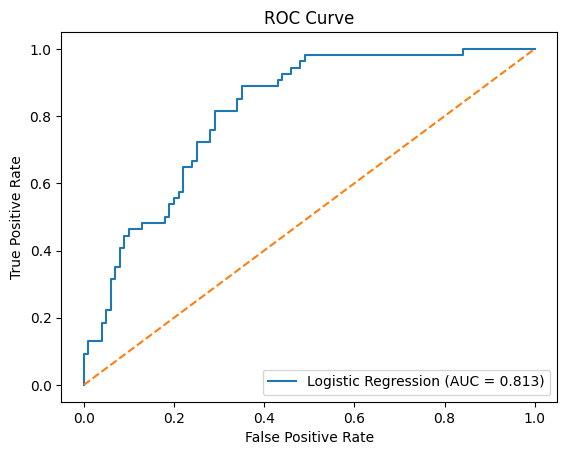

In [26]:
# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot ROC curve
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')

# Plot random classifier reference line
plt.plot([0, 1], [0, 1], '--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [27]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



In [28]:
feature_importance = pd.DataFrame({'Feature': X_train.columns,'Coefficient': model.coef_[0]})

feature_importance = feature_importance.sort_values(by='Coefficient',ascending=False)

print(feature_importance)

                    Feature  Coefficient
1                   Glucose     1.183483
5                       BMI     0.709592
0               Pregnancies     0.372902
6  DiabetesPedigreeFunction     0.287734
7                       Age     0.186434
3             SkinThickness     0.013980
2             BloodPressure    -0.014612
4                   Insulin    -0.044609


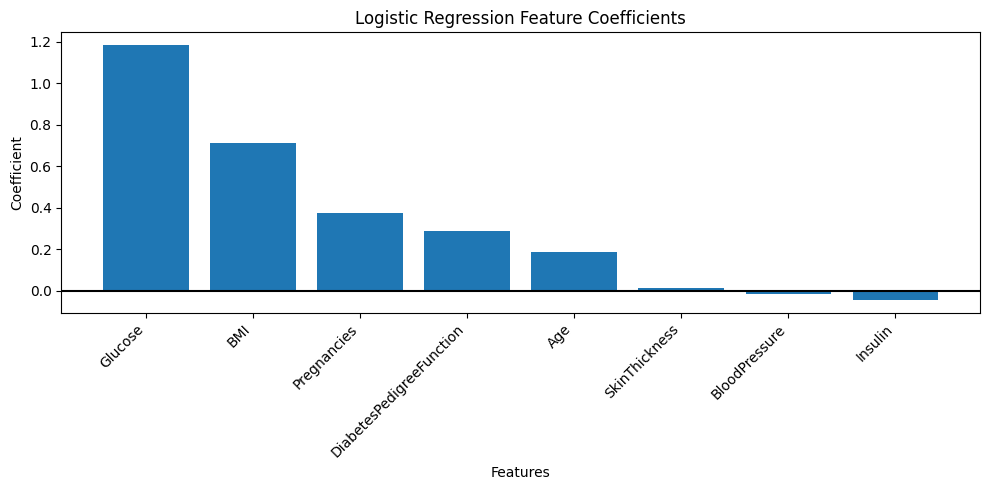

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(feature_importance['Feature'],feature_importance['Coefficient'])

plt.xticks(rotation=45, ha='right')
plt.axhline(y=0, color='black')
plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Features')
plt.ylabel('Coefficient')
plt.tight_layout()
plt.show()

In [30]:
from sklearn.linear_model import LogisticRegression

model_normal = LogisticRegression(random_state=42)

model_normal.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [31]:
y_pred_normal = model_normal.predict(X_test_scaled)

In [32]:
from sklearn.metrics import classification_report

print("BALANCED MODEL")
print(classification_report(y_test, y_pred))

print("NORMAL MODEL")
print(classification_report(y_test, y_pred_normal))

BALANCED MODEL
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

NORMAL MODEL
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

